# Captum tour: capacity probes

The two models are described in `01_data_and_models`.

In [1]:
from toy import *  # shared setup: data, the two models (trained once, then cached), helpers

## 21. `captum.module` stochastic gates: what the model can do without

```python
gates = BinaryConcreteStochasticGates(n, reg_weight=price)    # n learnable on/off gates
h, penalty = gates(h)                         # h * gates;  penalty = price × expected number of open gates
loss = cross_entropy(scores, y) + penalty     # fine-tune for 10 epochs
kept = gates.get_gate_active_probs() > 0.5    # the values worth their price
```

* plot 1: gates on the **16 input features** (feature selection), `BinaryConcrete` and `Gaussian` versions
* plot 2: gates on the outputs of `fc1`, `fc2`, `fc3`, at three prices

gated fine-tunes in 3s


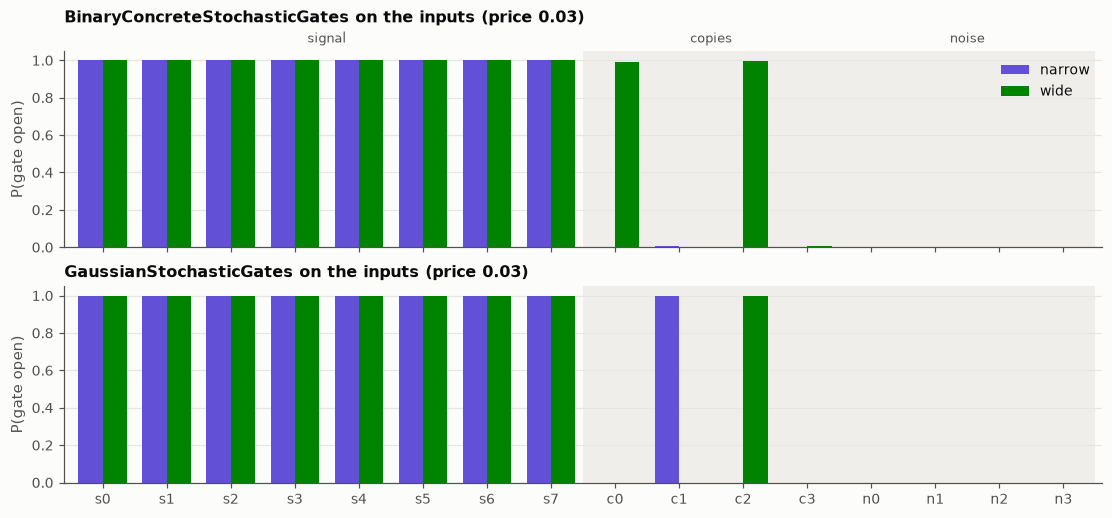

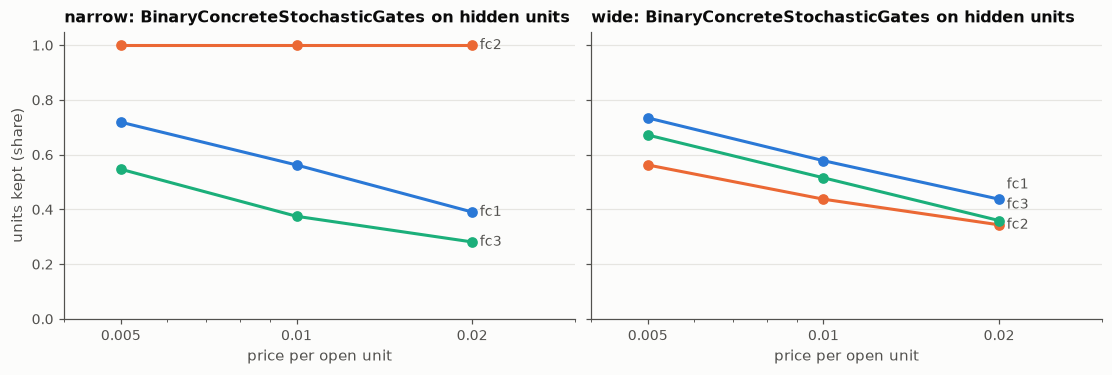

In [2]:

t0 = time.time()
input_open = {}
for kind, cls in GATES.items():
    for name in WIDTH:
        torch.manual_seed(0)
        g = finetune_with_gates(InputGated(load(WIDTH[name], CKPTS[name][EPOCHS]), cls(N_FEATURES, reg_weight=0.03)))
        input_open[(kind, name)] = g.gates.get_gate_active_probs().detach()
PRICES = [0.005, 0.01, 0.02]
hidden_kept = hidden_gates_kept(PRICES)  # in toy.py
print(f"gated fine-tunes in {time.time() - t0:.0f}s")

fig, axes = plt.subplots(2, 1, figsize=(10, 4.6), sharex=True)
for ax, kind in zip(axes, GATES):
    for k, name in enumerate(["narrow", "wide"]):
        ax.bar(np.arange(N_FEATURES) + (k - 0.5) * 0.38, input_open[(kind, name)].numpy(), width=0.38,
               color=MODEL_COLOR[name], label=name)
    feature_axis(ax, ticklabels=(ax is axes[-1]), group_labels=(ax is axes[0]))
    ax.set_ylim(0, 1.05)
    ax.set_ylabel("P(gate open)")
    ax.set_title(f"{kind} on the inputs (price 0.03)", loc="left")
axes[0].legend(loc="upper right")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 3.3), sharey=True)
for ax, name in zip(axes, ["narrow", "wide"]):
    for layer in LAYERS:
        d = hidden_kept[(hidden_kept.model == name) & (hidden_kept.layer == layer)]
        ax.plot(d.price, d.kept, marker="o", color=LAYER_COLOR[layer])
    ax.set_xscale("log")
    ax.set_xticks(PRICES, [str(p) for p in PRICES])
    ax.xaxis.set_minor_formatter(plt.NullFormatter())
    ax.set_xlim(0.004, 0.03)
    ax.set_ylim(0, 1.05)
    ax.set_xlabel("price per open unit")
    ax.set_title(f"{name}: BinaryConcreteStochasticGates on hidden units", loc="left")
    last = hidden_kept[(hidden_kept.model == name) & (hidden_kept.price == PRICES[-1])]
    end_labels(ax, [(PRICES[-1], v, layer) for layer, v in zip(last.layer, last.kept)])
axes[0].set_ylabel("units kept (share)")
plt.show()

* On the inputs, both gate types keep all eight signals and close all the noise. One or two copies stay open: a copy
  carries almost the same information as its signal, so keeping either costs the same price.
* On the hidden units, narrow `fc2` keeps all 3 units at every price, while `fc1` and `fc3` shed 25–70% of theirs. In the
  wide model, `fc2` sheds units like the other layers. The narrow `fc2` cannot afford to lose anything.

## 22. `TCAV` (`captum.concept`): which layers still carry each feature

```python
concept "s7 high" = examples with s7 > 1;   random = ordinary examples       # one concept per feature
for layer in [fc1, fc2, fc3]:
    a_c, a_r = layer output for the concept / random examples
    accuracy = logistic regression test accuracy, a_c vs a_r        # plot 1 (0.5 = the layer lost it)
    cav = mean(a_c) - mean(a_r)                                    # the concept's direction
    tcav_score = share of class-0 examples where (d score[0] / d layer output) · cav > 0      # plot 2
```

The classifier is pluggable (`Classifier`). Captum 0.9's default reports ~50% accuracy for every two-concept set
(it takes an argmax over a single column), so a small one is plugged in.

TCAV in 4s


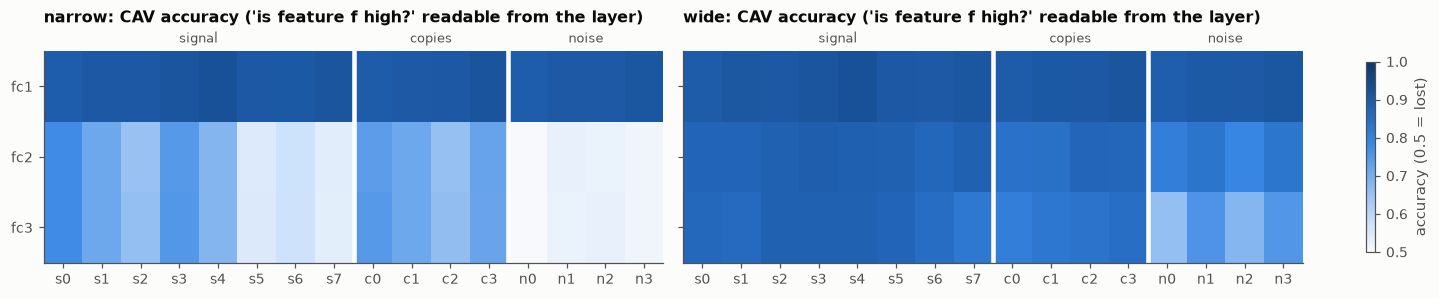

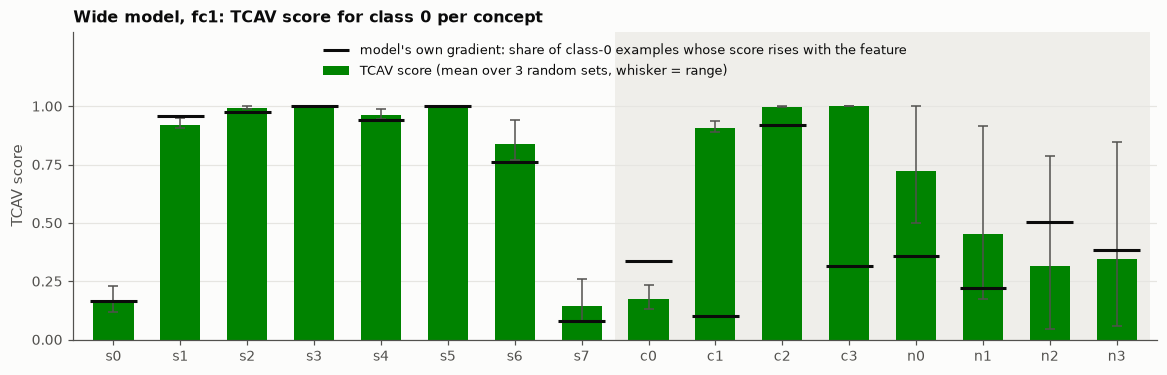

TCAV scores of random concepts against each other: [0. 0. 1.]


In [3]:
sets = [[c, r] for c in concepts for r in randoms] + [[randoms[1], randoms[0]], [randoms[2], randoms[0]],
                                                      [randoms[2], randoms[1]]]
cav_acc, tcav_score = {}, {}
t0 = time.time()
for name, model in MODELS.items():  # run_tcav, ConceptCAV and the concept sets are in toy.py
    acc, score = run_tcav(name, model, sets)
    cav_acc.update(acc)
    tcav_score.update(score)
print(f"TCAV in {time.time() - t0:.0f}s")

fig, axes = plt.subplots(1, 2, figsize=(13, 2.6), sharey=True)
for ax, name in zip(axes, ["narrow", "wide"]):
    grid = np.array([[np.mean([cav_acc[(name, layer, c.name, r.name)] for r in randoms]) for c in concepts]
                     for layer in LAYERS])
    im = feature_heatmap(ax, grid, LAYERS, vmin=0.5, vmax=1.0)
    ax.set_title(f"{name}: CAV accuracy ('is feature f high?' readable from the layer)", loc="left")
fig.colorbar(im, ax=axes, shrink=0.9, label="accuracy (0.5 = lost)")
plt.show()

# reference for the TCAV score: the model's own input gradient for the class
xt = X_CLASS.clone().requires_grad_(True)
WIDE(xt)[:, TCAV_CLASS].sum().backward()
rises = (xt.grad > 0).float().mean(0)
s = np.array([[tcav_score[("wide", "fc1", c.name, r.name)] for r in randoms] for c in concepts])
random_pairs = [tcav_score[("wide", "fc1", a.name, b.name)] for a, b in [(randoms[1], randoms[0]), (randoms[2], randoms[0]),
                                                                        (randoms[2], randoms[1])]]
fig, ax = plt.subplots(figsize=(10.5, 3.3))
ax.bar(range(N_FEATURES), s.mean(1), color=MODEL_COLOR["wide"], width=0.6,
       label="TCAV score (mean over 3 random sets, whisker = range)")
ax.errorbar(range(N_FEATURES), s.mean(1), yerr=[s.mean(1) - s.min(1), s.max(1) - s.mean(1)], fmt="none",
            ecolor=INK2, capsize=3, lw=1)
ax.hlines(rises.numpy(), np.arange(N_FEATURES) - 0.35, np.arange(N_FEATURES) + 0.35, color=INK, lw=2,
          label=f"model's own gradient: share of class-{TCAV_CLASS} examples whose score rises with the feature")
feature_axis(ax)
ax.set_ylim(0, 1.32)
ax.set_yticks([0, 0.25, 0.5, 0.75, 1])
ax.set_ylabel("TCAV score")
ax.set_title(f"Wide model, fc1: TCAV score for class {TCAV_CLASS} per concept", loc="left")
ax.legend(loc="upper center", fontsize=8.5, ncol=1)
plt.show()
print("TCAV scores of random concepts against each other:", np.round(random_pairs, 2))

* **Where features survive**: `fc1` still carries every feature in both models, noise included. In the narrow model
  the weak signals `s5`–`s7` are close to chance from `fc2` on: they were lost in the bottleneck. Noise is gone there
  too. Wide `fc2` still carries every feature, even the noise: it has room to spare.
* **TCAV scores** match the model's own gradient direction for all eight signals, with tight whiskers. Concepts are
  sets of examples, so correlated features travel together: the "`c1` high" examples also have `s1` high, so `c1`
  gets `s1`'s score.
* The noise concepts land anywhere from 0 to 1 depending on the random set, and random concepts score 0 or 1 against
  each other. That is what an unreliable TCAV score looks like: always repeat against several random sets.

## 23. `captum.robust`: adversarial checks

```python
FGSM:  x_adv = x + ε * sign(d loss / d x)             # one step that hurts the true class most
PGD:   10 steps of size ε/4, kept within ±ε of x;   mask = attack only the chosen features
MinParamPerturbation:  smallest ε for which model(x_adv) is wrong      (binary search)
AttackComparator:      accuracy under each attack, or under any input transform (here: removing feature groups)
```

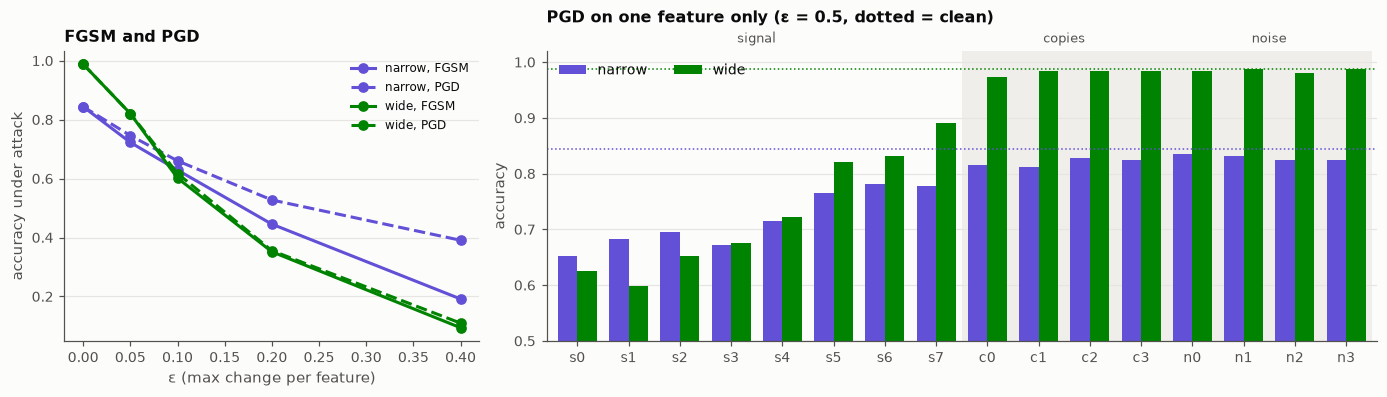

,narrow,wide
MinParamPerturbation: median ε to flip,0.190,0.140
accuracy (no attack),0.844,0.988
FGSM ε=0.1,0.629,0.602
remove s0-s3,0.195,0.238
remove s4-s7,0.570,0.609
remove copies,0.793,0.977
remove noise,0.832,0.957


In [4]:
EPS = [0.05, 0.1, 0.2, 0.4]
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.5), gridspec_kw=dict(width_ratios=[1, 2]))
for name, model in MODELS.items():
    fgsm, pgd = FGSM(model), PGD(model)
    clean = loss_acc(model, PX, PY)[1]
    for attack, ls in [("FGSM", "-"), ("PGD", "--")]:
        accs = [clean]
        for eps in EPS:
            if attack == "FGSM":
                xa = fgsm.perturb(PX, epsilon=eps, target=PY)
            else:
                xa = pgd.perturb(PX, radius=eps, step_size=eps / 4, step_num=10, target=PY)
            accs.append(loss_acc(model, xa, PY)[1])
        axes[0].plot([0] + EPS, accs, ls=ls, marker="o", color=MODEL_COLOR[name], label=f"{name}, {attack}")
    per_feature = []
    for j in range(N_FEATURES):  # attack one feature at a time
        mask = torch.zeros(1, N_FEATURES)
        mask[0, j] = 1
        per_feature.append(loss_acc(model, pgd.perturb(PX, radius=0.5, step_size=0.1, step_num=10, target=PY,
                                                       mask=mask), PY)[1])
    k = list(WIDTH).index(name)
    axes[1].bar(np.arange(N_FEATURES) + (k - 0.5) * 0.38, per_feature, width=0.38, color=MODEL_COLOR[name], label=name)
    axes[1].axhline(clean, color=MODEL_COLOR[name], lw=1, ls=":")
axes[0].set_xlabel("ε (max change per feature)")
axes[0].set_ylabel("accuracy under attack")
axes[0].set_title("FGSM and PGD", loc="left")
axes[0].legend(fontsize=8)
feature_axis(axes[1], group_labels=True)
axes[1].set_ylim(0.5, 1.02)
axes[1].set_ylabel("accuracy")
axes[1].set_title("PGD on one feature only (ε = 0.5, dotted = clean)", loc="left")
axes[1].legend(loc="upper left", ncol=2)
plt.show()


def accuracy_metric(out, target):
    return (out.argmax(-1) == target).float().mean()


def remove(cols):
    def transform(inputs):
        inputs = inputs.clone()
        inputs[:, cols] = 0.0
        return inputs
    return transform


rows = {}
for name, model in MODELS.items():
    fgsm = FGSM(model)
    search = MinParamPerturbation(model, attack=fgsm, arg_name="epsilon", arg_min=0.0, arg_max=2.0,
                                  arg_step=0.01, mode="binary")
    eps_needed = [search.evaluate(PX[i:i + 1], target=PY[i:i + 1], attack_kwargs={"target": PY[i:i + 1]})[1]
                  for i in range(48)]
    eps_needed = [e for e in eps_needed if e is not None and e > 0]  # skip examples already wrong
    comparator = AttackComparator(forward_func=model, metric=accuracy_metric)
    comparator.add_attack(fgsm, "FGSM ε=0.1", attack_kwargs={"epsilon": 0.1}, additional_attack_arg_names=["target"])
    for label, cols in [("remove s0-s3", [0, 1, 2, 3]), ("remove s4-s7", [4, 5, 6, 7]),
                        ("remove copies", [8, 9, 10, 11]), ("remove noise", [12, 13, 14, 15])]:
        comparator.add_attack(remove(cols), label)
    result = comparator.evaluate(PX, target=PY)
    rows[name] = {"MinParamPerturbation: median ε to flip": float(np.median(eps_needed)),
                  **{k: float(v["mean"] if isinstance(v, dict) else v) for k, v in result.items()}}
display(pd.DataFrame(rows).rename(index={"Original": "accuracy (no attack)"}))

* Attacking one feature at a time shows where each model is vulnerable: through the signals (most through `s0`–`s3`),
  not through copies or noise.
* A better fit is not a more robust one: the wide model loses accuracy faster under FGSM and PGD and flips at a
  smaller ε. Robustness checks answer a different question than capacity.
* `AttackComparator` with "remove a feature group" transforms: removing the copies costs the narrow model about
  5 points and the wide model 1. The narrow model still leans on the copies.